# Learning within a session

Do people learn Rush Hour within a session, and how much? And how would a student calibrated to people learn - with and without a teacher?

**Humans** (`scripts/human_data.py`): the paper's 42 participants, each given 60 minutes to solve as many of 70 puzzles (optimal length 5, 9, 12 or 14) as they could, in random order, with no feedback beyond solving. They could restart or surrender a puzzle. Lengths here count the final slide of the red car out, as this repo does: the paper's lengths 5/9/12/14 are 6/10/13/15 (`human_data.distance`).

**Simulated participants** (`scripts/session_experiment.py`, `rl.learning_session`): a pure-intuition student plays one puzzle at a time, in its own random order, and learns online, after every human trial's worth of puzzles, from those puzzles only - nothing earlier is replayed, and there is no validation and no going back to an earlier, better version of itself. The **calibrated student** (below) was fitted to the humans in steps:
- **starting point and giving up** - after each move the student surrenders with a probability shaped like people's (by moves made relative to the optimal length, fitted to the human data; `--surrender`), which ends the puzzle unsolved and untaught. The rates are scaled (`--surrender-scale`), and the scale and the pretrained network are fitted together (`scripts/p3_session/fit_surrender.py`) so the student starts where people do in their first 10 trials: 87% solved at 2.76x optimal. Best fit: 6 rounds of pretraining (`round6_epoch01.pt`) at 0.4x people's surrender rates - 88% solved at 2.67x, and close at every length. The fit uses the session's own pool puzzles: on the humans' 70 layouts no pretrained network reaches people's level even without surrender (at best 73% solved at 3.5x), so those layouts are harder for the student than pool puzzles of the same length;
- **more data than a person** - the network learns far less from each example than people, so each human trial stands for 30 simulated puzzles (`--multiplier 30`);
- **a clean learning signal** - loops are cut out of every solved attempt (`--window -1`) and each update makes 3 passes (`--steps 3`); without either, the student barely learned. A restart after an unsolved attempt made no difference, so there is one attempt per puzzle.

How the earlier version (round 3, unscaled surrender) compared, without a teacher (calibrated before the length convention was fixed, on puzzles one move shorter than the humans' - worth re-checking): it started close (2.84x optimal in the first 10 trials, humans 2.82x with lengths counted the same way; solved 80% vs 87%), improves about half as fast as people over the first 30 trials (-3% moves per 10 trials vs -6%), and keeps improving afterwards, while people level off and give up more often late in the session.

Two measures: the session as it was played (the analogue of the human curve; with a teacher's help, if any) and held-out tests along the way (the student's current network, untaught, giving up as people do; it doesn't learn from them). Error bars are standard errors across participants / students, so they include differences between learners.

In [1]:
import sys
sys.path.append("../scripts")
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import human_data as hd
import session_experiment as se
import teach_experiment as te

## Humans

`trend` estimates the within-person change per 10 trials, comparing each person with themselves and each puzzle with itself, separately for the trials before and after `SPLIT` - in the human data, moves / optimal falls early in the session and then levels off, so one slope over the whole session hides the learning. The raw curve by trial number also mixes in who gets that far: participants who reach trial 60 are the faster ones.

In [2]:
BLOCK = 10  # trials per point on the learning curves
SPLIT = 30  # within-learner trends are estimated for trials 1..SPLIT and after

humans = hd.trials()
per_person = humans.groupby("subject").size()
print(f"{humans.subject.nunique()} participants, {len(humans)} puzzles played "
      f"({per_person.mean():.0f} each on average, {per_person.min()}-{per_person.max()})")
solved = humans[humans.solved]
print(pd.DataFrame({"played": humans.groupby("optimal").size(),
                    "solved": humans.groupby("optimal").solved.mean().round(2),
                    "median moves / optimal (solved)": (solved.moves / solved.optimal).groupby(solved.optimal).median().round(2)}))


def curve(df, person, block=BLOCK):
    """Per block of trials: (first trial, solve rate, moves / optimal over solved puzzles, people), means and
    standard errors across people of each person's own average in the block."""
    df = df.assign(block=(df.trial - 1) // block)
    out = []
    for b, d in df.groupby("block"):
        solve = d.groupby(person).solved.mean()
        won = d[d.solved]
        ratio = (won.moves / won.distance).groupby(won[person]).mean()
        out.append((b * block + 1, te.mean_se(list(solve)), te.mean_se(list(ratio)), d[person].nunique()))
    return out


def trends(df, learner, person, puzzle, split=SPLIT):
    """Rows of within-learner change per 10 puzzles (solve rate; log moves / optimal over solved puzzles -
    -0.05 is about 5% fewer moves), for trials 1..split and after."""
    df = df.assign(solved_f=df.solved.astype(float))
    rows = []
    for label, part in ((f"1-{split}", df[df.trial <= split]), (f"{split + 1}+", df[df.trial > split])):
        if part.empty:
            continue
        won = part[part.solved].assign(log_ratio=lambda d: np.log(d.moves / d.distance))
        (sb, sse), (rb, rse) = (hd.trend(part, "solved_f", person=person, puzzle=puzzle),
                                hd.trend(won, "log_ratio", person=person, puzzle=puzzle))
        rows.append({"learner": learner, "trials": label, "solve rate / 10 puzzles": f"{sb:+.1%} ± {sse:.1%}",
                     "log moves/optimal / 10 puzzles": f"{rb:+.3f} ± {rse:.3f}"})
    return rows


human_curve = curve(humans, "subject")
human_trends = trends(humans, "humans", "subject", "instance")
print(pd.DataFrame(human_trends).to_string(index=False))

42 participants, 2283 puzzles played (54 each on average, 20-70)
         played  solved  median moves / optimal (solved)
optimal                                                 
5           583    0.98                             1.60
9           595    0.89                             2.00
12          567    0.86                             2.00
14          538    0.73                             2.43


learner trials solve rate / 10 puzzles log moves/optimal / 10 puzzles
 humans   1-30            +0.3% ± 1.0%                 -0.062 ± 0.015
 humans    31+            -1.9% ± 1.2%                 +0.031 ± 0.013


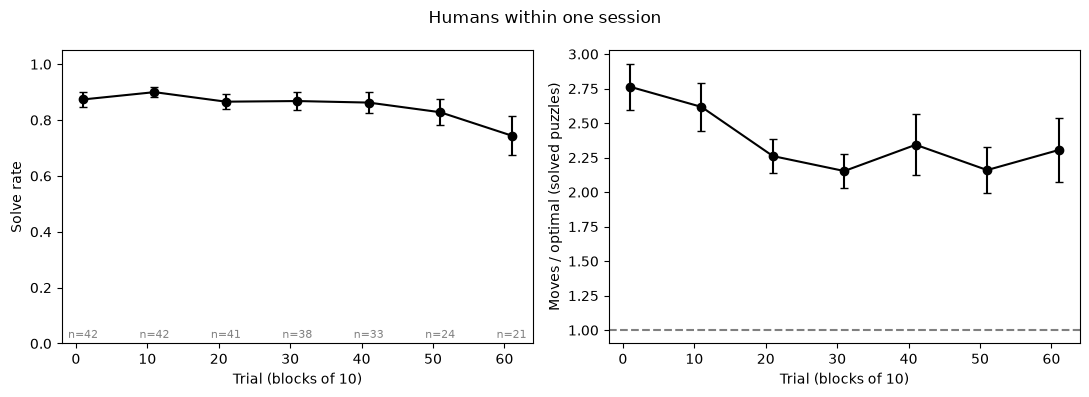

In [3]:
def plot_curve(ax, points, which, color, label, offset=0.0):
    xs = [p[0] + offset for p in points]
    ax.errorbar(xs, [p[which][0] for p in points], yerr=[p[which][1] if p[which][1] == p[which][1] else 0 for p in points],
                marker="o", capsize=3, color=color, label=label)


fig, (ax_solve, ax_ratio) = plt.subplots(1, 2, figsize=(11, 4))
plot_curve(ax_solve, human_curve, 1, "black", "humans")
plot_curve(ax_ratio, human_curve, 2, "black", "humans")
for x, _, _, n in human_curve:
    ax_solve.annotate(f"n={n}", (x, 0.02), ha="center", fontsize=8, color="gray")
ax_solve.set_ylim(0, 1.05)
ax_solve.set_ylabel("Solve rate")
ax_ratio.set_ylabel("Moves / optimal (solved puzzles)")
ax_ratio.axhline(1.0, color="gray", linestyle="--")
for ax in (ax_solve, ax_ratio):
    ax.set_xlabel(f"Trial (blocks of {BLOCK})")
fig.suptitle("Humans within one session")
plt.tight_layout()
os.makedirs("../visualization/p3_session", exist_ok=True)
plt.savefig("../visualization/p3_session/human_session.png")
plt.show()

## Simulated sessions

The calibrated student's settings are in `CALIBRATED` below. To train it with teachers, run from `scripts/` (it uses every CPU core - run one thing at a time):

```
python session_experiment.py fitted_teachers --teachers none random:0.1 correct-after:0.1 --students 8 --multiplier 30 --lr 1e-4 --window -1 --steps 3 --max-attempts 1 --surrender --test-surrender --surrender-scale 0.4 --init ../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt
```

or set `RUN_HERE = True` in the next cell (which includes the Bayesian teacher below) (the notebook is busy until it finishes). Each condition takes roughly 20-30 minutes on 8 cores - about 1.5 hours for these three (a teacher searches each new puzzle once for its optimal moves, about 0.1 s each, a few extra minutes per student). The run saves after each condition, and the plots below show whatever has finished. `"none"` is the no-teacher baseline, so all the conditions sit in one run. (`fitted_teachers` also has `flag:0.1`, a teacher that only pointed mistakes out, played before it was retired - `future_old/flag_mistakes.py`; its saved results still plot. Its `correct-after:0.1` was played when that teacher also pointed the mistake out, as a move to avoid; it now only shows the move.)

Each student does 72 human trials = 2,160 simulated puzzles; the teacher teaches on all of them, so its budget is counted per simulated puzzle. Students are tested every 18 trials on 20 held-out puzzles per length, 3 attempts each. `--test-only` re-tests a saved run (e.g. with other `--test-runs`); `--overwrite` deletes it and starts over. The simulated puzzles are drawn from the pool at the humans' lengths (6/10/13/15 by default since the length fix; earlier runs used 5/9/12/14), not the humans' own 70 puzzles.

**The Bayesian teacher** (`teach.Bayesian`, `bayes:0.1`) is adaptive, after Chen et al. (2024, hierarchical Bayesian teaching) and Shachnai et al. (2025, when parents take over). It holds beliefs about its student - its skill (the chance a move of its own is optimal) at each distance from the goal around an overall level with a population prior, how hard the current puzzle is for it, and how persistent it is (people's surrender rates times a factor) - and updates them from every move the student plays itself, older puzzles counting less as the student learns. On each turn it plans ahead, as Shachnai et al.'s parents do: is the student's chance of solving before it gives up or runs out of moves raised enough by showing the optimal move to be worth the cost? It averages that over its belief about the puzzle's difficulty, as Chen et al.'s teachers marginalise over what the learner knows. The cost adjusts itself so it shows about 10% of moves, the same budget as `random:0.1`, never looking at the move the student intends. To add it to the finished run, run the same command with only the new teacher - a saved run re-run with the same settings adds the teachers it doesn't have and leaves the rest:

```
python session_experiment.py fitted_teachers --teachers bayes:0.1 --students 8 --multiplier 30 --lr 1e-4 --window -1 --steps 3 --max-attempts 1 --surrender --test-surrender --surrender-scale 0.4 --init ../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt
```

In [4]:
INIT = "../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt"
CALIBRATED = ["--students", "8", "--multiplier", "30", "--lr", "1e-4", "--window", "-1", "--steps", "3",
              "--max-attempts", "1", "--surrender", "--test-surrender", "--surrender-scale", "0.4", "--init", INIT]
TEACHERS = ["none", "random:0.1", "correct-after:0.1", "bayes:0.1"]  # finished ones are skipped

RUN_HERE = False  # True: train and test here (hours; the notebook is busy until done)
if RUN_HERE:
    os.chdir("../scripts")  # relative paths (--init) are resolved from where the run starts
    try:
        se.main(["fitted_teachers", "--teachers", *TEACHERS, *CALIBRATED])
    finally:
        os.chdir("../notebooks")

In [5]:
RUNS = ["fitted_teachers", "agency_only", "agency_progress"]  # saved runs under models/sessions, each plotted on its own
OUT = se.OUT
COLORS = {"none": "C7", "random": "C0", "correct-after": "C1", "flag": "C2", "correct-before": "C3", "bayes": "C4"}  # by kind of teacher

runs = {}
for name in RUNS:
    if not os.path.exists(os.path.join(OUT, name, "config.json")):
        print(f"{name}: not run yet")
        continue
    runs[name] = se.load_session(name, OUT)
for name, run in runs.items():
    c = run["config"]
    print(f"{name}: teachers {', '.join(c['teachers'])}; {c['students']} students x "
          f"{c['per_bin']} trials per length {c['session_bins']} x multiplier {se.multiplier(c)}; lr {c['lr']}, "
          f"steps {c['steps']}, window {c['window']}, encode {c['encode']}, attempts per puzzle {c['max_attempts']}, "
          f"surrender {c.get('surrender', False)} x {c.get('surrender_scale', 1.0)} (tests {c.get('test_surrender', False)}); "
          f"shown moves teach x {c.get('shown_weight', 1.0)}, progress labels x {c.get('progress_weight', 0.0)} "
          f"(tail {c.get('progress_tail', 0.2)}); init {c['init']}")
    for teacher, entry in run["teachers"].items():
        missing = [what for what, key in (("sessions", "sessions"), ("tests", "results")) if not entry[key]]
        if missing:
            print(f"  {teacher}: no {' or '.join(missing)} saved yet - still running, or the run stopped early")

fitted_teachers: teachers none, random:0.1, correct-after:0.1, flag:0.1, bayes:0.1; 8 students x 18 trials per length ['6-6', '10-10', '13-13', '15-15'] x multiplier 30; lr 0.0001, steps 3, window -1, encode 1.0, attempts per puzzle 1, surrender True x 0.4 (tests True); shown moves teach x 1.0, progress labels x 0.0 (tail 0.2); init /Users/john/Documents/GitHub/rush-hour/models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt
agency_only: teachers random:0.1, bayes:0.1; 8 students x 18 trials per length ['6-6', '10-10', '13-13', '15-15'] x multiplier 30; lr 0.0001, steps 3, window -1, encode 1.0, attempts per puzzle 1, surrender True x 0.4 (tests True); shown moves teach x 0.0, progress labels x 0.0 (tail 0.2); init /Users/john/Documents/GitHub/rush-hour/models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt
agency_progress: teachers none, random:0.1, bayes:0.1; 8 students x 18 trials per length ['6-6', '10-10', '13-13', '15-15'] x multiplier 30; lr 0.0001, steps 3, window -1, encode 1.0, a

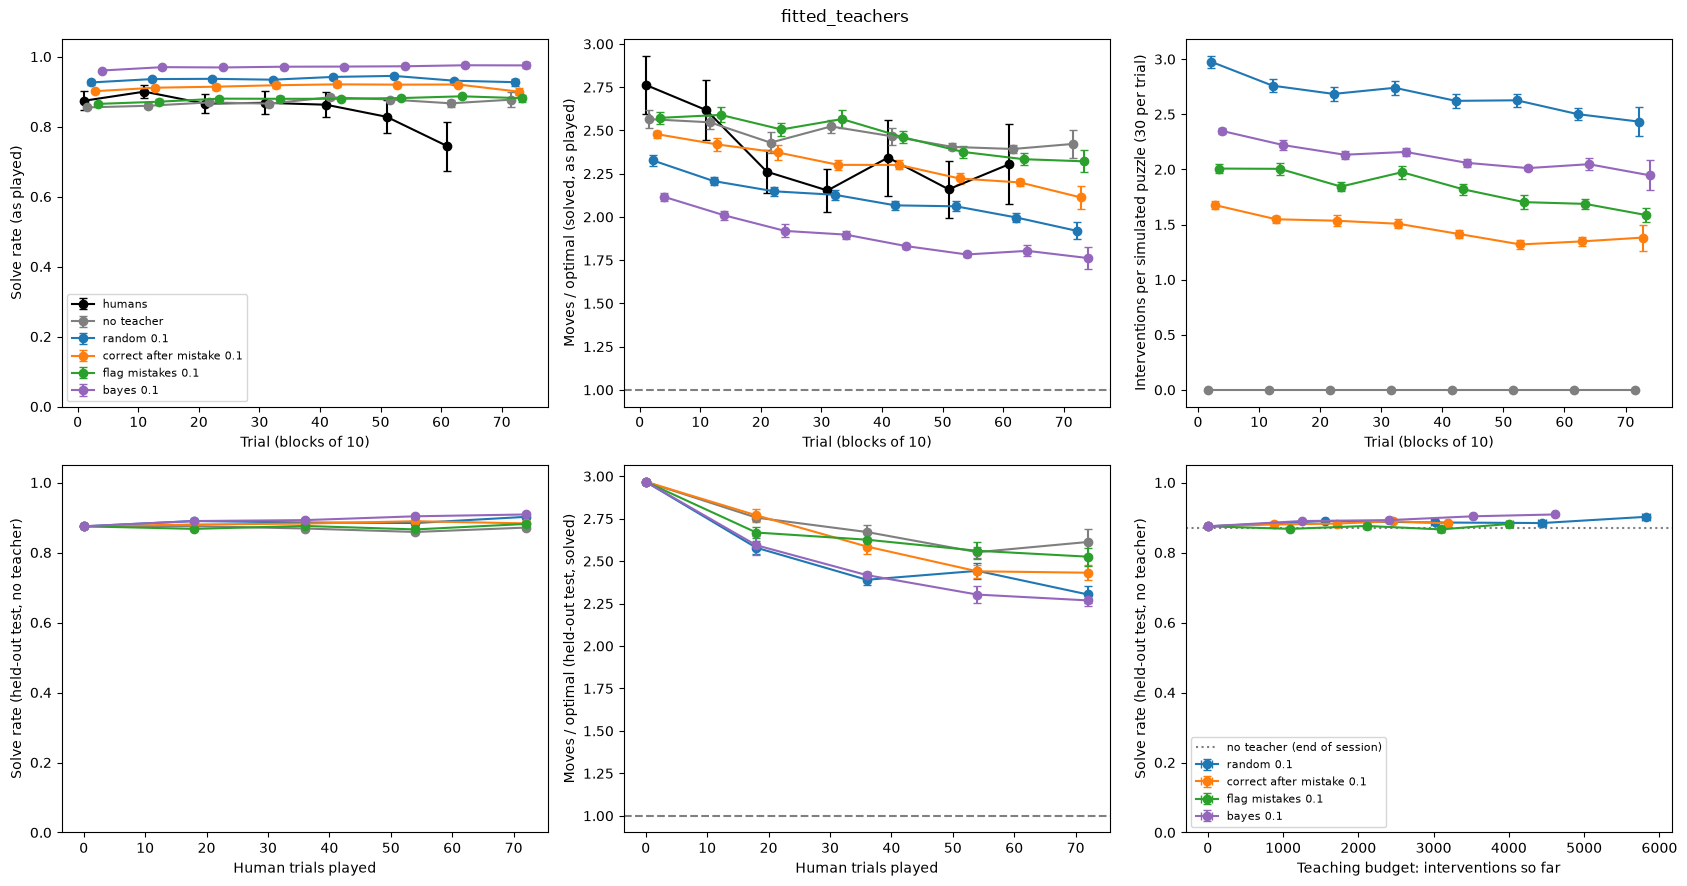

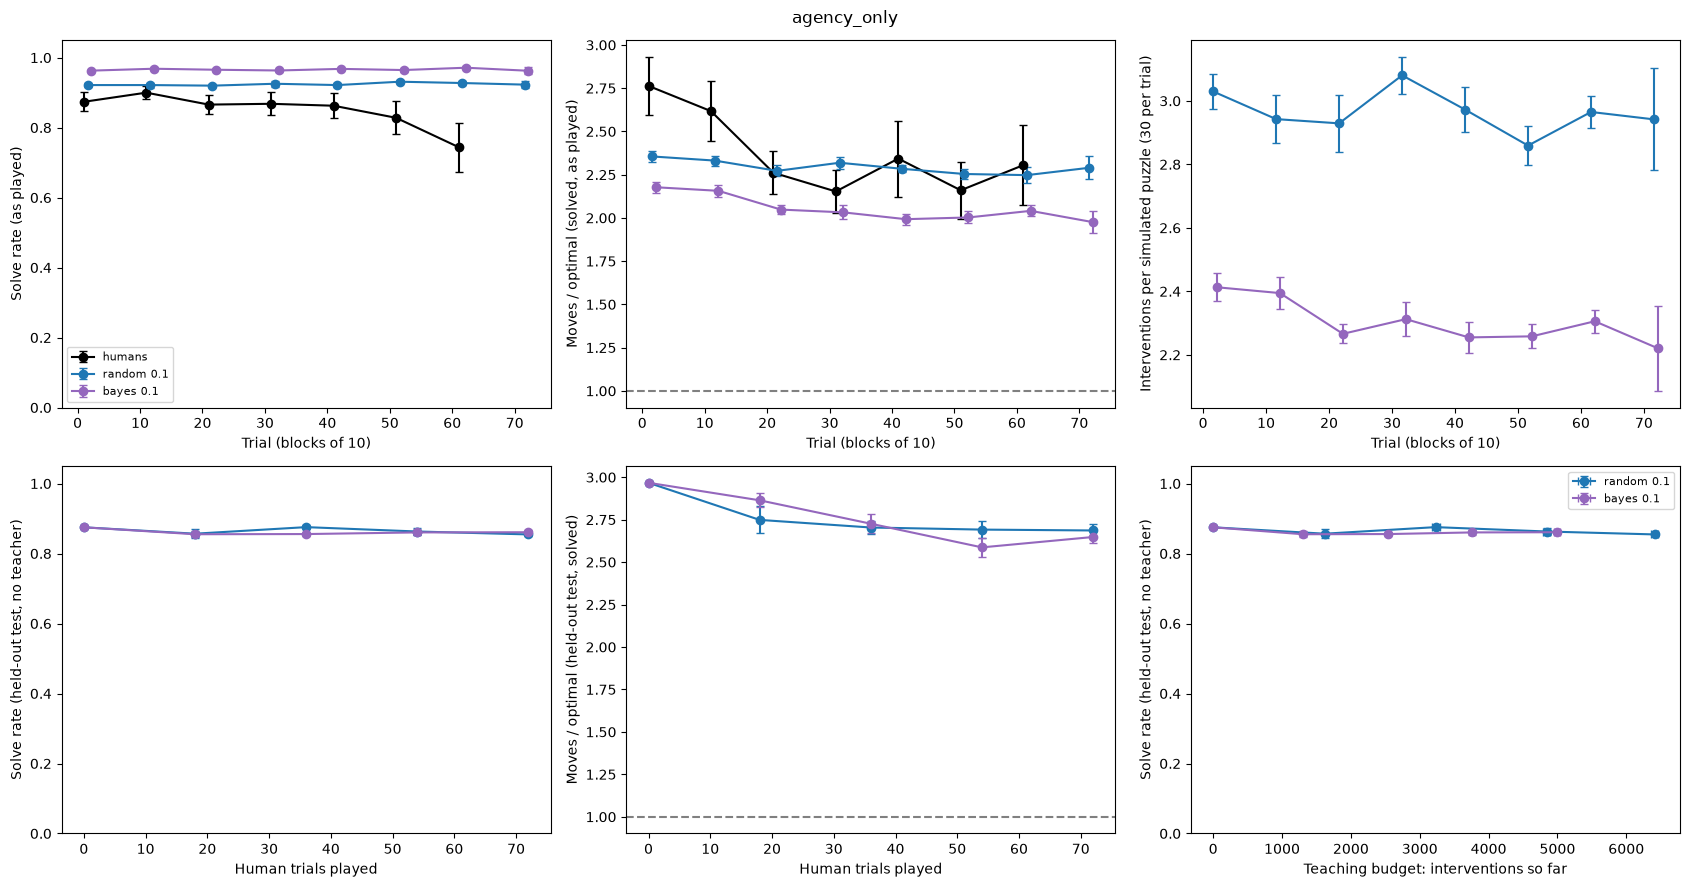

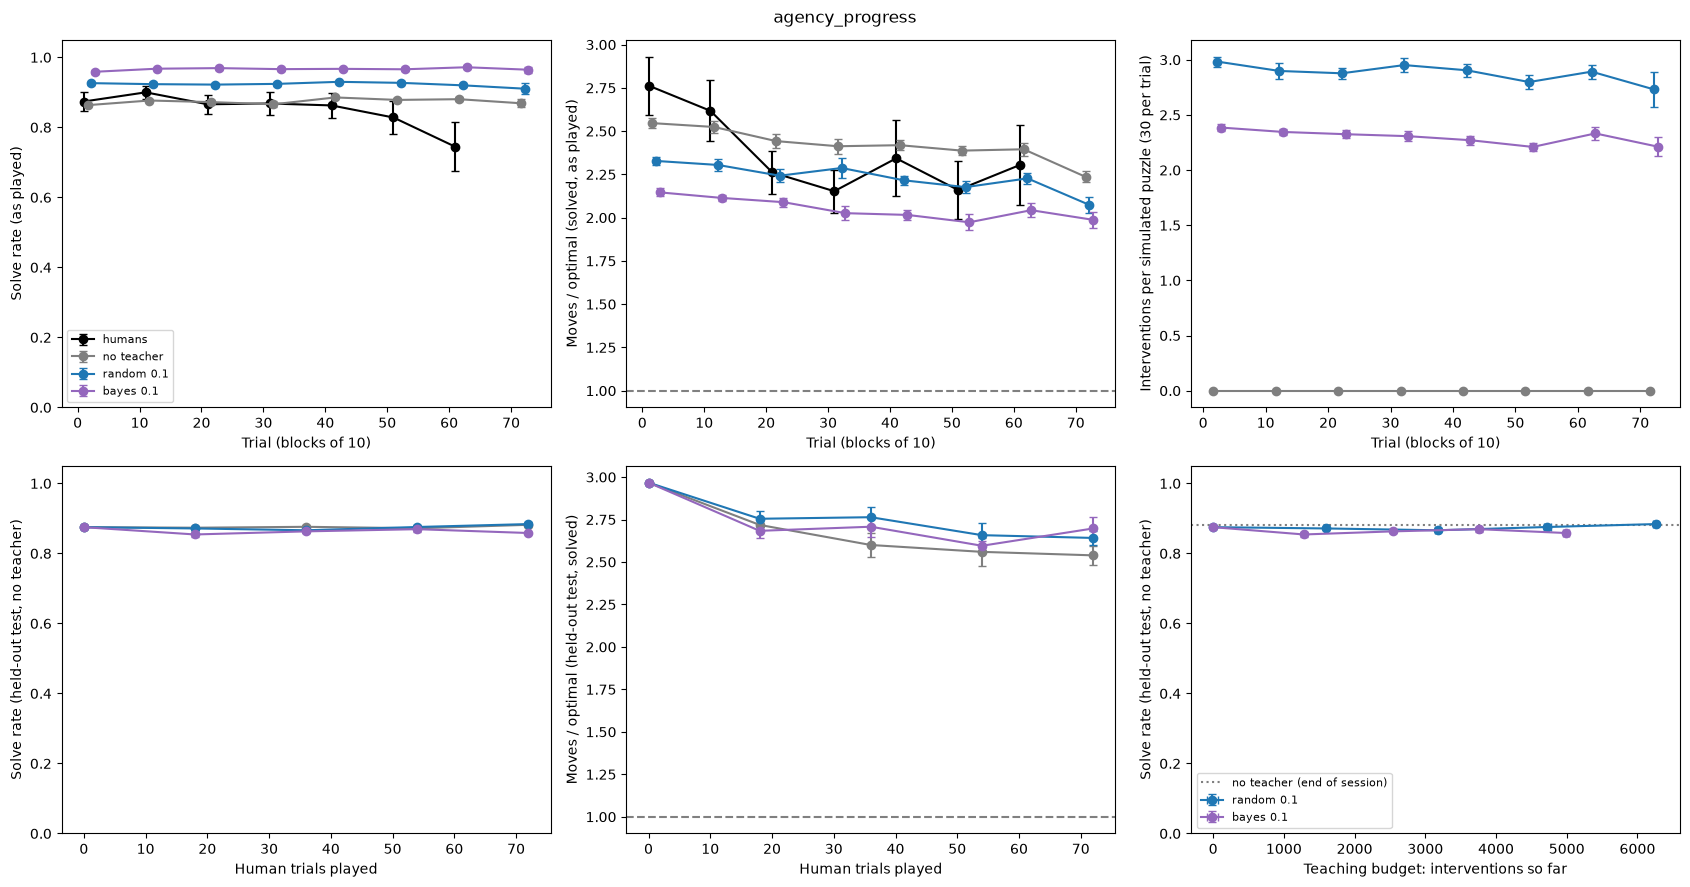

In [6]:
def budget_at(sessions, n):
    """Interventions during the session up to `n` simulated puzzles played, (mean, standard error) across students."""
    return te.mean_se([sum(e["interventions"] for e in record[:n]) for record in sessions.values()])


def err(stat):
    return stat[1] if stat[1] == stat[1] else 0


for name, run in runs.items():
    c = run["config"]
    m = se.multiplier(c)
    fig, axes = plt.subplots(2, 3, figsize=(17, 9))
    (ax_solve, ax_ratio, ax_help), (ax_test, ax_test_ratio, ax_budget) = axes
    plot_curve(ax_solve, human_curve, 1, "black", "humans")
    plot_curve(ax_ratio, human_curve, 2, "black", "humans")
    for k, (spec, (teacher, entry)) in enumerate(zip(c["teachers"], run["teachers"].items())):
        color = COLORS[spec.partition(":")[0]]
        offset = (k + 1) * 0.6
        if entry["sessions"]:
            df = pd.DataFrame([e | {"student": s} for s, record in entry["sessions"].items() for e in record])
            points = curve(df, "student")
            plot_curve(ax_solve, points, 1, color, teacher, offset)
            plot_curve(ax_ratio, points, 2, color, teacher, offset)
            blocks = se.session_curve(entry["sessions"], BLOCK)
            ax_help.errorbar([b[0] + offset for b in blocks], [b[3][0] for b in blocks], yerr=[err(b[3]) for b in blocks],
                             marker="o", capsize=3, color=color, label=teacher)
        if entry["results"]:
            tests = se.test_curve(entry["results"], c["test_runs"])
            xs = [n / m for n, _ in tests]
            for ax, key in ((ax_test, "solve rate"), (ax_test_ratio, "moves / optimal")):
                ax.errorbar(xs, [r[key][0] for _, r in tests], yerr=[err(r[key]) for _, r in tests],
                            marker="o", capsize=3, color=color, label=teacher)
            if entry["sessions"] and not any(e["interventions"] for record in entry["sessions"].values() for e in record):
                ax_budget.axhline(tests[-1][1]["solve rate"][0], color=color, linestyle=":",
                                  label=f"{teacher} (end of session)")  # no budget spent: a reference level
            elif entry["sessions"]:
                spent = [budget_at(entry["sessions"], n) for n, _ in tests]
                ax_budget.errorbar([b[0] for b in spent], [r["solve rate"][0] for _, r in tests],
                                   xerr=[err(b) for b in spent], yerr=[err(r["solve rate"]) for _, r in tests],
                                   marker="o", capsize=3, color=color, label=teacher)
    ax_solve.set_ylabel("Solve rate (as played)")
    ax_solve.set_ylim(0, 1.05)
    ax_ratio.set_ylabel("Moves / optimal (solved, as played)")
    ax_ratio.axhline(1.0, color="gray", linestyle="--")
    for ax in (ax_solve, ax_ratio, ax_help):
        ax.set_xlabel(f"Trial (blocks of {BLOCK})")
    ax_help.set_ylabel(f"Interventions per simulated puzzle ({m} per trial)")
    for ax in (ax_test, ax_test_ratio):
        ax.set_xlabel("Human trials played")
    ax_test.set_ylabel("Solve rate (held-out test, no teacher)")
    ax_test.set_ylim(0, 1.05)
    ax_test_ratio.set_ylabel("Moves / optimal (held-out test, solved)")
    ax_test_ratio.axhline(1.0, color="gray", linestyle="--")
    ax_budget.set_xlabel("Teaching budget: interventions so far")
    ax_budget.set_ylabel("Solve rate (held-out test, no teacher)")
    ax_budget.set_ylim(0, 1.05)
    ax_budget.legend(fontsize=8)
    ax_solve.legend(fontsize=8)
    fig.suptitle(name)
    plt.tight_layout()
    plt.savefig(f"../visualization/p3_session/session_{name}.png")
    plt.show()

In [7]:
rows = [{"run": "-"} | row for row in human_trends]
for name, run in runs.items():
    for teacher, entry in run["teachers"].items():
        if not entry["sessions"]:
            continue
        df = pd.DataFrame([e | {"student": s} for s, record in entry["sessions"].items() for e in record])
        rows += [{"run": name} | row for row in trends(df, teacher, "student", "puzzle")]
print("Within-learner change per 10 puzzles, as played (students with a teacher are helped while playing):")
print(pd.DataFrame(rows).to_string(index=False))

Within-learner change per 10 puzzles, as played (students with a teacher are helped while playing):
            run                   learner trials solve rate / 10 puzzles log moves/optimal / 10 puzzles
              -                    humans   1-30            +0.3% ± 1.0%                 -0.062 ± 0.015
              -                    humans    31+            -1.9% ± 1.2%                 +0.031 ± 0.013
fitted_teachers                no teacher   1-30            +0.1% ± 0.5%                 -0.021 ± 0.007
fitted_teachers                no teacher    31+            -0.1% ± 0.2%                 -0.012 ± 0.003
fitted_teachers                random 0.1   1-30            +0.1% ± 0.3%                 -0.031 ± 0.005
fitted_teachers                random 0.1    31+            -0.1% ± 0.2%                 -0.016 ± 0.003
fitted_teachers correct after mistake 0.1   1-30            +0.6% ± 0.4%                 -0.025 ± 0.006
fitted_teachers correct after mistake 0.1    31+            -0.2% ± 

## Agency: what shown moves teach

Under the default, a move the teacher shows teaches exactly like one the student found itself - it becomes a training example, and on a solved puzzle it also labels the earlier boards of the path. `--shown-weight λ` scales everything a shown move teaches by λ (`rl.agency_weights`): the example on the board where it was shown, and the destination labels it set on earlier boards. At λ = 0 the student learns only from its own moves, so help can still let it finish a puzzle but cannot hand it the answer.

**Progress labels** (`--progress-weight`, `rl.progress_examples`) let the student learn from the moves that didn't work. A frozen copy of its starting network's value head (moves to go) rates each move it played itself on a puzzle it struggled with (unsolved, or moves cut out as loops); the moves rated the clearest steps forward (top `--progress-tail` of its recent moves) become "play this move here", and the clearest steps back become "play any other legal move", which lowers the bad move's probability within the usual policy loss. On a solved path with no loops every move already has a better label, so the labels come only from struggle - which a teacher's help removes.

Both runs have the calibrated student's settings and seeds, so student k sees the same puzzles in the same order as in `fitted_teachers`; `agency_only` has no no-teacher condition of its own (λ only changes what shown moves teach) and is compared with `fitted_teachers`' (λ = 1, no progress labels). Each run took about 1.5-2 hours:

```
python session_experiment.py agency_only --teachers random:0.1 bayes:0.1 --shown-weight 0 --students 8 --multiplier 30 --lr 1e-4 --window -1 --steps 3 --max-attempts 1 --surrender --test-surrender --surrender-scale 0.4 --init ../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt
python session_experiment.py agency_progress --teachers none random:0.1 bayes:0.1 --shown-weight 0 --progress-weight 0.25 --students 8 --multiplier 30 --lr 1e-4 --window -1 --steps 3 --max-attempts 1 --surrender --test-surrender --surrender-scale 0.4 --init ../models/teach/fresh_p0.1/random_0.1/round6_epoch01.pt
```

Below: each teacher's held-out test at the end of the session against the no-teacher students of the same settings, paired by student (so the puzzles and their order match). Results so far (2026-11-03): with λ = 1 both teachers beat no teacher (random +0.031, Bayesian +0.038 solve rate); with λ = 0 help costs (random -0.017, Bayesian -0.010), so the teachers' whole benefit came from what shown moves taught. Progress labels give the no-teacher student a little (0.882 vs 0.871, within the run-to-run noise of about 0.01 - sessions aren't exactly reproducible), but the Bayesian teacher, which keeps the student solving 97% of puzzles as played, leaves it a fifth of the no-teacher student's labels and ends lowest (-0.023, all 8 students). The Bayesian teacher maximises solving in the session, which is the wrong target once help has a cost.

End of session, held-out test (no teacher); vs none: paired by student, mean ± standard error


,run,teacher,shown weight,progress weight,solved as played,shown per puzzle,progress labels (fwd/back),test solve rate,test moves / optimal,solve rate vs none,moves / optimal vs none
0,fitted_teachers,no teacher,1.0,0.00,0.868,0.000,0/0,0.871,2.613,,
1,fitted_teachers,random 0.1,1.0,0.00,0.936,2.694,0/0,0.902,2.303,+0.031 ± 0.007 (7/8 > 0),-0.309 ± 0.095 (1/8 > 0)
2,fitted_teachers,bayes 0.1,1.0,0.00,0.970,2.134,0/0,0.909,2.269,+0.038 ± 0.006 (8/8 > 0),-0.344 ± 0.088 (0/8 > 0)
3,agency_only,random 0.1,0.0,0.00,0.924,2.968,0/0,0.855,2.686,-0.017 ± 0.005 (0/8 > 0),+0.074 ± 0.065 (6/8 > 0)
4,agency_only,bayes 0.1,0.0,0.00,0.966,2.312,0/0,0.861,2.648,-0.010 ± 0.008 (2/8 > 0),+0.035 ± 0.095 (5/8 > 0)
5,agency_progress,no teacher,0.0,0.25,0.874,0.000,6078/8595,0.882,2.539,,
6,agency_progress,random 0.1,0.0,0.25,0.924,2.896,3146/5008,0.884,2.642,+0.002 ± 0.007 (5/8 > 0),+0.103 ± 0.084 (5/8 > 0)
7,agency_progress,bayes 0.1,0.0,0.25,0.967,2.308,1084/2098,0.858,2.697,-0.023 ± 0.004 (0/8 > 0),+0.158 ± 0.039 (8/8 > 0)


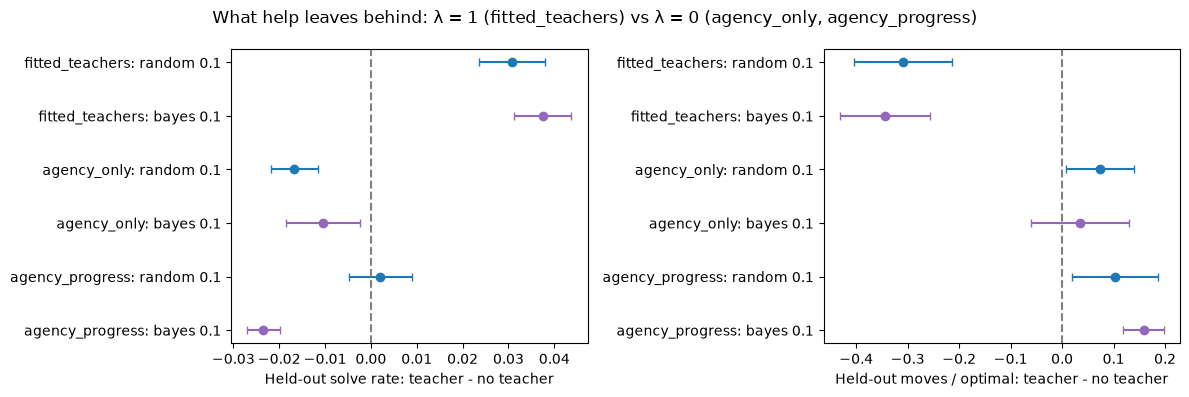

In [8]:
COMPARE = {"fitted_teachers": "fitted_teachers", "agency_only": "fitted_teachers", "agency_progress": "agency_progress"}  # run: whose no-teacher students it is compared with


def final_per_student(entry, run):
    """Each student's held-out (solve rate, moves / optimal) at the end of the session."""
    n_runs = run["config"]["test_runs"]
    out = {}
    for s, by_n in entry["results"].items():
        summary = te.summarize(by_n[max(by_n)], n_runs)
        out[s] = (summary["solve rate"][0], summary["moves / optimal"][0])
    return out


rows, diffs = [], []
for name, run in runs.items():
    base_name = COMPARE.get(name, name)
    if base_name not in runs or not runs[base_name]["teachers"].get("no teacher", {}).get("results"):
        continue
    base = final_per_student(runs[base_name]["teachers"]["no teacher"], runs[base_name])
    c = run["config"]
    for spec, (teacher, entry) in zip(c["teachers"], run["teachers"].items()):
        if not entry["results"] or not entry["sessions"] or spec.startswith(("flag", "correct-after")):
            continue
        end = final_per_student(entry, run)
        played = [e for record in entry["sessions"].values() for e in record]
        labels = {k: sum(e.get("progress_labels", {}).get(k, 0) for e in played) / len(entry["sessions"])
                  for k in ("forward", "back")}
        row = {"run": name, "teacher": teacher, "shown weight": c.get("shown_weight", 1.0),
               "progress weight": c.get("progress_weight", 0.0),
               "solved as played": np.mean([e["solved"] for e in played]),
               "shown per puzzle": np.mean([e["interventions"] for e in played]),
               "progress labels (fwd/back)": f"{labels['forward']:.0f}/{labels['back']:.0f}",
               "test solve rate": np.mean([v[0] for v in end.values()]),
               "test moves / optimal": np.mean([v[1] for v in end.values()])}
        if not (spec == "none" and base_name == name):
            for k, key in enumerate(("solve rate", "moves / optimal")):
                d = [end[s][k] - base[s][k] for s in end]
                mean, se_ = te.mean_se(d)
                row[f"{key} vs none"] = f"{mean:+.3f} ± {se_:.3f} ({sum(x > 0 for x in d)}/{len(d)} > 0)"
                diffs.append((name, teacher, key, mean, se_))
        rows.append(row)
print("End of session, held-out test (no teacher); vs none: paired by student, mean ± standard error")
display(pd.DataFrame(rows).round(3).fillna(""))

if diffs:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    names = list(dict.fromkeys(d[0] for d in diffs))
    for ax, key in zip(axes, ("solve rate", "moves / optimal")):
        pts = [d for d in diffs if d[2] == key]
        for i, (name, teacher, _, mean, se_) in enumerate(pts):
            ax.errorbar(mean, i, xerr=se_, marker="o", capsize=3,
                        color=COLORS[runs[name]["config"]["teachers"][list(runs[name]["teachers"]).index(teacher)].partition(":")[0]])
        ax.set_yticks(range(len(pts)), [f"{n}: {t}" for n, t, *_ in pts])
        ax.axvline(0, color="gray", linestyle="--")
        ax.set_xlabel(f"Held-out {key}: teacher - no teacher")
        ax.invert_yaxis()
    fig.suptitle("What help leaves behind: λ = 1 (fitted_teachers) vs λ = 0 (agency_only, agency_progress)")
    plt.tight_layout()
    plt.savefig("../visualization/p3_session/session_agency.png")
    plt.show()

## What the Bayesian teacher believed

Per block of trials and puzzle length, averaged over students: the teacher's belief, at the start of each puzzle, of the chance the student's next move is optimal there (on a typical puzzle - it should rise as the student learns); the chance it gave the student of solving that puzzle on its own; the moves it showed per puzzle; and its cost per move shown (in solves), which it adjusts to keep to its budget.

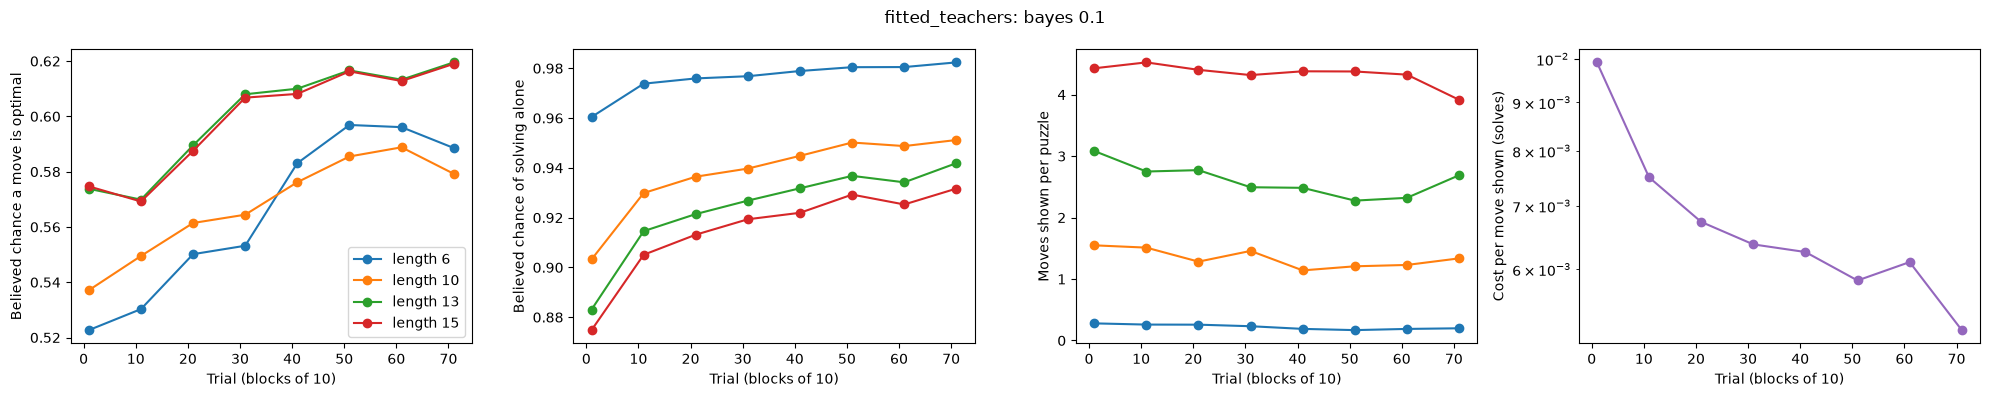

bayes 0.1: shows 0.100 of moves after the first 10 trials


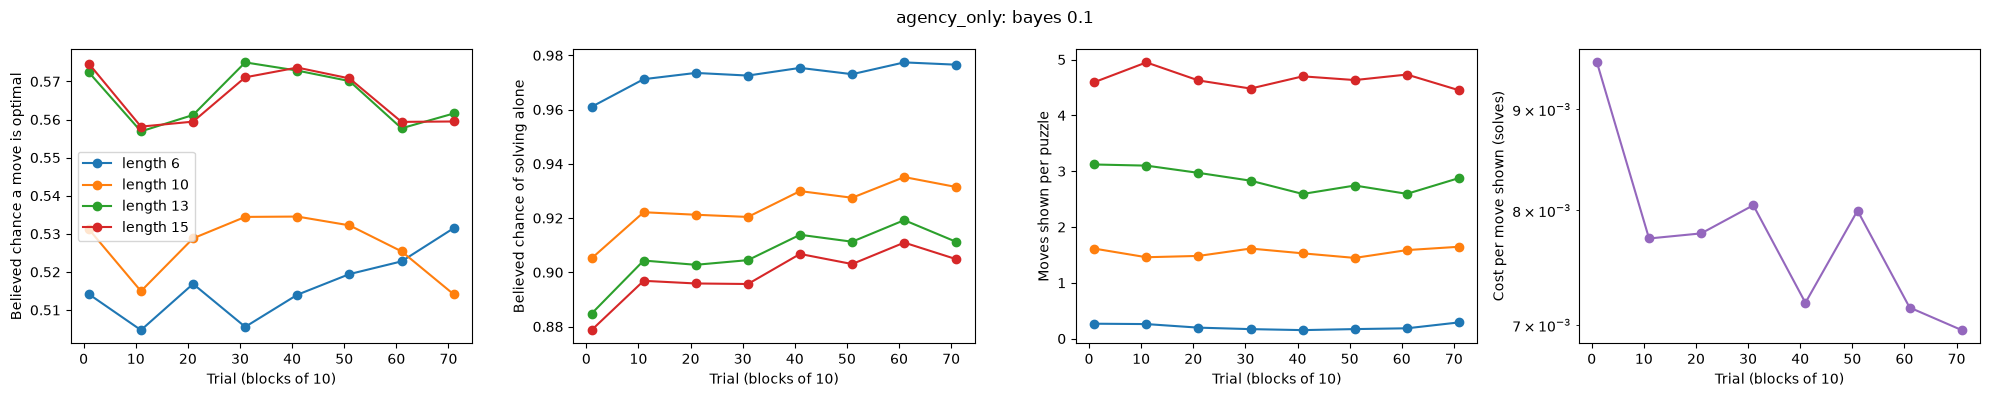

bayes 0.1: shows 0.099 of moves after the first 10 trials


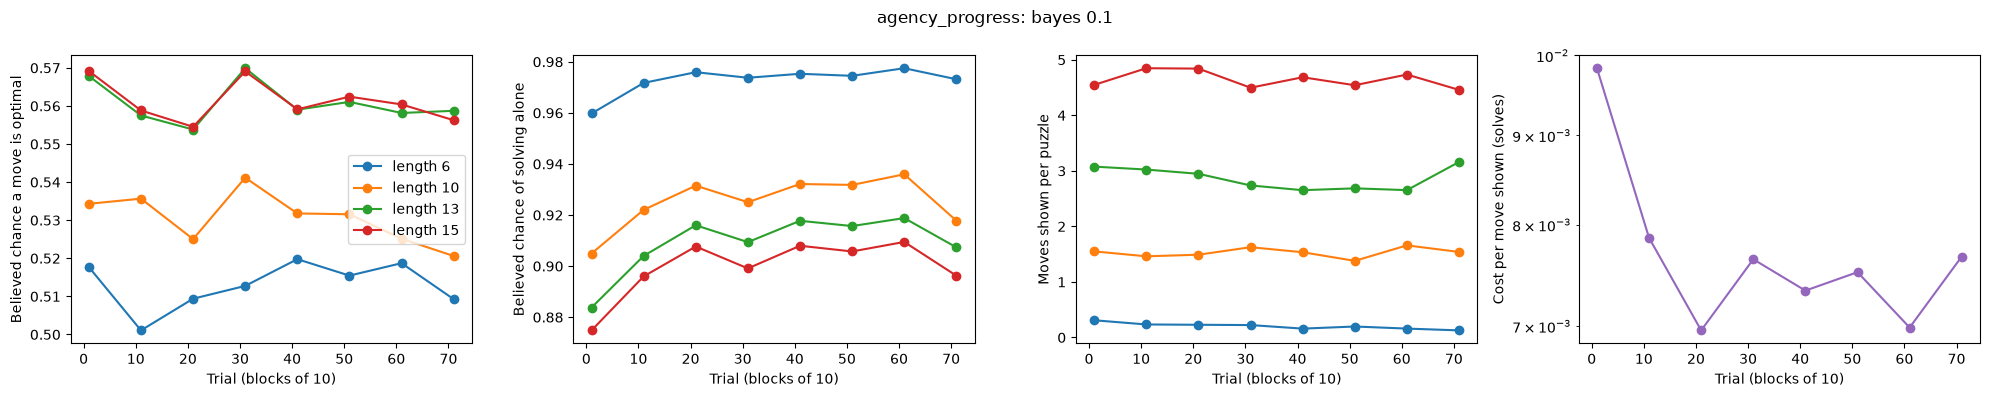

bayes 0.1: shows 0.100 of moves after the first 10 trials


In [9]:
for name, run in runs.items():
    c = run["config"]
    for spec, (teacher, entry) in zip(c["teachers"], run["teachers"].items()):
        if spec.partition(":")[0] != "bayes" or not entry["sessions"]:
            continue
        df = pd.DataFrame([e | e["teacher_counts"] | {"student": s} for s, record in entry["sessions"].items()
                           for e in record])
        df["shown"] = df.get("shown", pd.Series(0, index=df.index)).fillna(0)
        df["block"] = (df.trial - 1) // BLOCK * BLOCK + 1
        fig, axes = plt.subplots(1, 4, figsize=(20, 4))
        panels = (("skill_at_start", "Believed chance a move is optimal"), ("predicted_solve", "Believed chance of solving alone"),
                  ("shown", "Moves shown per puzzle"))
        for ax, (column, label) in zip(axes, panels):
            for d, line in df.groupby(["block", "distance"])[column].mean().unstack().items():
                ax.plot(line.index, line.values, marker="o", label=f"length {d}")
            ax.set_ylabel(label)
        axes[3].plot(*zip(*df.groupby("block").cost.mean().items()), marker="o", color="C4")
        axes[3].set_ylabel("Cost per move shown (solves)")
        axes[3].set_yscale("log")
        for ax in axes:
            ax.set_xlabel(f"Trial (blocks of {BLOCK})")
        axes[0].legend()
        fig.suptitle(f"{name}: {teacher}")
        plt.tight_layout()
        plt.show()
        late = df[df.trial > BLOCK]
        print(f"{teacher}: shows {late.shown.sum() / late.moves.sum():.3f} of moves after the first {BLOCK} trials")
